In [3]:
%pip install opencv-python matplotlib
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

import cv2
import matplotlib.pyplot as plt

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 8.3 MB/s eta 0:00:06
   -- ------------------------------------- 2.4/44.0 MB 7.7 MB/s eta 0:00:06
   ---- ----------------------------------- 5.2/44.0 MB 10.4 MB/s eta 0:00:04
   ------ --------------------------------- 7.3/44.0 MB 10.4 MB/s eta 0:00:04
   -------- ------------------------------- 9.7/44.0 MB 10.6 MB/s eta 0:00:04
   ---------- ----------------------------- 11.8/44.0 MB 10.4 MB/s eta 0:00:04
   ------------ --------------------------- 14.2/44.0 MB 10.5 MB/s eta 0:00:03
   --------------- ------------------------ 16.8/44.0 MB 10.7 MB/s eta 0:00:03
   ----------------- ---------------------- 19.1/44.0 MB 10.9 MB/s eta 0:00:03
   ------------------- -------------------- 21.8/44.0 MB 10.9 MB/s eta 0:00:03
   --------------------- ------------------ 24.1/44.0 MB 11.0 MB/s eta 0:00:02
   ------------------------ --------------- 26.7/44.0 MB 11.0 MB/s e


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import cv2
import matplotlib.pyplot as plt

print("OpenCV :", cv2.__version__)
print("Matplotlib :", plt.matplotlib.__version__)

OpenCV : 5.0.0
Matplotlib : 3.10.9


In [5]:
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

import cv2
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "NEU-DET"
IMAGE_DIR = DATA_DIR / "IMAGES"
ANNOTATION_DIR = DATA_DIR / "ANNOTATIONS"

print("Dataset :", DATA_DIR)
print("Images  :", IMAGE_DIR)
print("XML     :", ANNOTATION_DIR)

Dataset : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET
Images  : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET\IMAGES
XML     : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET\ANNOTATIONS


In [6]:
images = sorted(IMAGE_DIR.glob("*.jpg"))
annotations = sorted(ANNOTATION_DIR.glob("*.xml"))

print(f"Nombre d'images      : {len(images)}")
print(f"Nombre d'annotations : {len(annotations)}")

Nombre d'images      : 1800
Nombre d'annotations : 1800


In [7]:
classes = [image.stem.rsplit("_", 1)[0] for image in images]

class_counts = Counter(classes)

print("Nombre de classes :", len(class_counts))
print()

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name:20s} : {count}")

Nombre de classes : 6

crazing              : 300
inclusion            : 300
patches              : 300
pitted_surface       : 300
rolled-in_scale      : 300
scratches            : 300


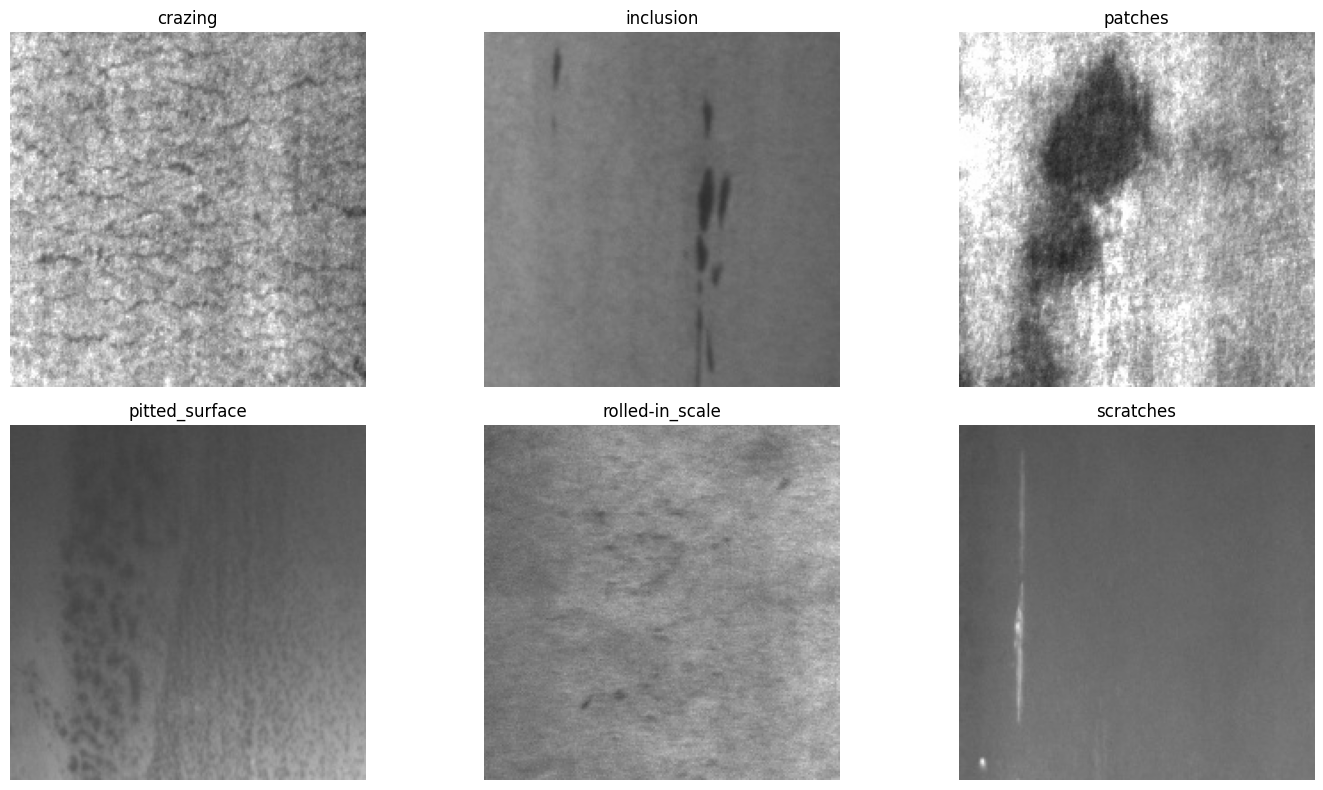

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, class_name in zip(axes.ravel(), sorted(class_counts)):
    # Chercher une image de cette classe
    image_path = next(
        image for image in images
        if image.stem.rsplit("_", 1)[0] == class_name
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
dimensions = Counter()

for image_path in images:
    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]
    dimensions[(width, height)] += 1

print("Dimensions des images :")

for dimension, count in dimensions.items():
    print(f"{dimension} : {count} images")

Dimensions des images :
(200, 200) : 1800 images


In [12]:
def read_annotation(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    objects = []

    for obj in root.findall("object"):
        class_name = obj.find("name").text
        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        objects.append({
            "class": class_name,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        })

    return objects

In [13]:
objects = read_annotation(annotations[0])

print(objects)

[{'class': 'crazing', 'xmin': 2, 'ymin': 2, 'xmax': 193, 'ymax': 194}]


In [14]:
def show_image_with_boxes(image_path, xml_path):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    objects = read_annotation(xml_path)

    for obj in objects:
        xmin = obj["xmin"]
        ymin = obj["ymin"]
        xmax = obj["xmax"]
        ymax = obj["ymax"]

        cv2.rectangle(
            image,
            (xmin, ymin),
            (xmax, ymax),
            (255, 0, 0),
            2
        )

        cv2.putText(
            image,
            obj["class"],
            (xmin, max(ymin - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            1
        )

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(image_path.stem)
    plt.show()

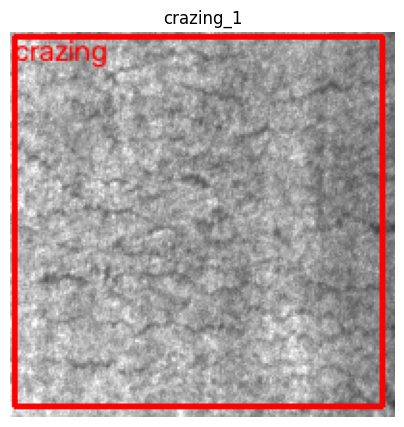

In [15]:
show_image_with_boxes(images[0], annotations[0])

In [16]:
total_objects = 0
invalid_boxes = []
annotation_classes = Counter()

for xml_path in annotations:
    try:
        objects = read_annotation(xml_path)

        for obj in objects:
            total_objects += 1
            annotation_classes[obj["class"]] += 1

            xmin = obj["xmin"]
            ymin = obj["ymin"]
            xmax = obj["xmax"]
            ymax = obj["ymax"]

            # Vérifier que la bounding box est valide
            if xmin >= xmax or ymin >= ymax:
                invalid_boxes.append({
                    "file": xml_path.name,
                    "box": (xmin, ymin, xmax, ymax)
                })

    except Exception as e:
        invalid_boxes.append({
            "file": xml_path.name,
            "error": str(e)
        })

print("Nombre total de défauts annotés :", total_objects)
print("\nRépartition des annotations :")

for class_name, count in sorted(annotation_classes.items()):
    print(f"{class_name:20s} : {count}")

print("\nAnnotations invalides :", len(invalid_boxes))

Nombre total de défauts annotés : 4189

Répartition des annotations :
crazing              : 689
inclusion            : 1011
patches              : 881
pitted_surface       : 432
rolled-in_scale      : 628
scratches            : 548

Annotations invalides : 0


In [17]:
image_names = {image.stem for image in images}
xml_names = {xml.stem for xml in annotations}

images_without_xml = image_names - xml_names
xml_without_image = xml_names - image_names

print("Images sans XML :", len(images_without_xml))
print("XML sans image  :", len(xml_without_image))

Images sans XML : 0
XML sans image  : 0


In [18]:
invalid_coordinates = []

for xml_path in annotations:
    objects = read_annotation(xml_path)

    # retrouver l'image correspondante
    image_path = IMAGE_DIR / f"{xml_path.stem}.jpg"

    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]

    for obj in objects:
        xmin = obj["xmin"]
        ymin = obj["ymin"]
        xmax = obj["xmax"]
        ymax = obj["ymax"]

        if not (
            0 <= xmin < xmax <= width
            and
            0 <= ymin < ymax <= height
        ):
            invalid_coordinates.append({
                "file": xml_path.name,
                "box": (xmin, ymin, xmax, ymax),
                "image_size": (width, height)
            })

print("Bounding boxes hors limites :", len(invalid_coordinates))

Bounding boxes hors limites : 0


In [19]:
objects_per_image = Counter()

for xml_path in annotations:
    objects = read_annotation(xml_path)
    objects_per_image[xml_path.stem] = len(objects)

distribution = Counter(objects_per_image.values())

print("Nombre de défauts par image :")

for nb_objects, nb_images in sorted(distribution.items()):
    print(f"{nb_objects} défaut(s) : {nb_images} images")

Nombre de défauts par image :
1 défaut(s) : 483 images
2 défaut(s) : 673 images
3 défaut(s) : 390 images
4 défaut(s) : 154 images
5 défaut(s) : 59 images
6 défaut(s) : 22 images
7 défaut(s) : 9 images
8 défaut(s) : 6 images
9 défaut(s) : 4 images


In [20]:
multi_class_images = []

for xml_path in annotations:
    objects = read_annotation(xml_path)

    classes_in_image = {obj["class"] for obj in objects}

    if len(classes_in_image) > 1:
        multi_class_images.append({
            "file": xml_path.name,
            "classes": sorted(classes_in_image)
        })

print("Images contenant plusieurs classes :", len(multi_class_images))

if multi_class_images:
    print("\nExemples :")
    for item in multi_class_images[:10]:
        print(item)

Images contenant plusieurs classes : 123

Exemples :
{'file': 'crazing_104.xml', 'classes': ['crazing', 'patches']}
{'file': 'crazing_105.xml', 'classes': ['crazing', 'inclusion']}
{'file': 'crazing_112.xml', 'classes': ['crazing', 'patches']}
{'file': 'crazing_152.xml', 'classes': ['crazing', 'patches']}
{'file': 'crazing_20.xml', 'classes': ['crazing', 'patches']}
{'file': 'patches_155.xml', 'classes': ['inclusion', 'patches']}
{'file': 'patches_167.xml', 'classes': ['inclusion', 'patches']}
{'file': 'patches_168.xml', 'classes': ['inclusion', 'patches']}
{'file': 'patches_171.xml', 'classes': ['inclusion', 'patches']}
{'file': 'patches_172.xml', 'classes': ['inclusion', 'patches']}


In [21]:
from collections import Counter

class_combinations = Counter()

for xml_path in annotations:
    objects = read_annotation(xml_path)

    classes_in_image = tuple(sorted({
        obj["class"]
        for obj in objects
    }))

    if len(classes_in_image) > 1:
        class_combinations[classes_in_image] += 1

print("Combinaisons de classes dans les images multi-classes :\n")

for combination, count in class_combinations.most_common():
    print(f"{' + '.join(combination):45s} : {count} images")

Combinaisons de classes dans les images multi-classes :

inclusion + scratches                         : 49 images
patches + pitted_surface                      : 36 images
inclusion + patches                           : 29 images
crazing + patches                             : 4 images
inclusion + pitted_surface                    : 2 images
crazing + inclusion                           : 1 images
inclusion + patches + pitted_surface          : 1 images
patches + pitted_surface + scratches          : 1 images


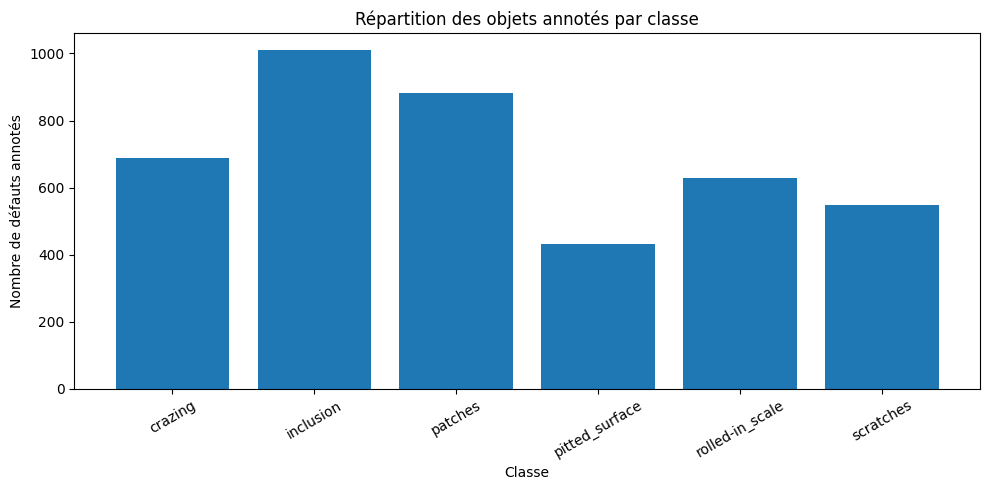

In [22]:
plt.figure(figsize=(10, 5))

class_names = sorted(annotation_classes)
class_values = [annotation_classes[name] for name in class_names]

plt.bar(class_names, class_values)

plt.title("Répartition des objets annotés par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre de défauts annotés")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [23]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "detection"

TRAIN_IMAGES_DIR = PROCESSED_DIR / "images" / "train"
VAL_IMAGES_DIR = PROCESSED_DIR / "images" / "val"
TEST_IMAGES_DIR = PROCESSED_DIR / "images" / "test"

TRAIN_LABELS_DIR = PROCESSED_DIR / "labels" / "train"
VAL_LABELS_DIR = PROCESSED_DIR / "labels" / "val"
TEST_LABELS_DIR = PROCESSED_DIR / "labels" / "test"

for directory in [
    TRAIN_IMAGES_DIR,
    VAL_IMAGES_DIR,
    TEST_IMAGES_DIR,
    TRAIN_LABELS_DIR,
    VAL_LABELS_DIR,
    TEST_LABELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Dossiers du dataset YOLO créés.")

Dossiers du dataset YOLO créés.


In [24]:
import sklearn
print(sklearn.__version__)

1.8.0


In [25]:
from sklearn.model_selection import train_test_split

# Toutes les images
image_paths = sorted(IMAGE_DIR.glob("*.jpg"))

# Classe principale indiquée dans le nom du fichier
image_classes = [
    image_path.stem.rsplit("_", 1)[0]
    for image_path in image_paths
]

# 70 % train, 30 % temporaire
train_images, temp_images, train_classes, temp_classes = train_test_split(
    image_paths,
    image_classes,
    test_size=0.30,
    random_state=42,
    stratify=image_classes
)

# Parmi les 30 % restants :
# 15 % validation + 15 % test
val_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=42,
    stratify=temp_classes
)

print("Train      :", len(train_images))
print("Validation :", len(val_images))
print("Test       :", len(test_images))

Train      : 1260
Validation : 270
Test       : 270


In [26]:
from collections import Counter

train_distribution = Counter(
    image_path.stem.rsplit("_", 1)[0]
    for image_path in train_images
)

val_distribution = Counter(
    image_path.stem.rsplit("_", 1)[0]
    for image_path in val_images
)

test_distribution = Counter(
    image_path.stem.rsplit("_", 1)[0]
    for image_path in test_images
)

print("TRAIN")
for class_name, count in sorted(train_distribution.items()):
    print(f"{class_name:20s} : {count}")

print("\nVALIDATION")
for class_name, count in sorted(val_distribution.items()):
    print(f"{class_name:20s} : {count}")

print("\nTEST")
for class_name, count in sorted(test_distribution.items()):
    print(f"{class_name:20s} : {count}")

TRAIN
crazing              : 210
inclusion            : 210
patches              : 210
pitted_surface       : 210
rolled-in_scale      : 210
scratches            : 210

VALIDATION
crazing              : 45
inclusion            : 45
patches              : 45
pitted_surface       : 45
rolled-in_scale      : 45
scratches            : 45

TEST
crazing              : 45
inclusion            : 45
patches              : 45
pitted_surface       : 45
rolled-in_scale      : 45
scratches            : 45


In [27]:
import shutil

def copy_images(image_paths, destination_dir):
    for image_path in image_paths:
        destination = destination_dir / image_path.name
        shutil.copy2(image_path, destination)


copy_images(train_images, TRAIN_IMAGES_DIR)
copy_images(val_images, VAL_IMAGES_DIR)
copy_images(test_images, TEST_IMAGES_DIR)

print("Images copiées avec succès.")
print("Train      :", len(list(TRAIN_IMAGES_DIR.glob("*.jpg"))))
print("Validation :", len(list(VAL_IMAGES_DIR.glob("*.jpg"))))
print("Test       :", len(list(TEST_IMAGES_DIR.glob("*.jpg"))))

Images copiées avec succès.
Train      : 1260
Validation : 270
Test       : 270


In [28]:
CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

CLASS_TO_ID = {
    class_name: class_id
    for class_id, class_name in enumerate(CLASS_NAMES)
}

print(CLASS_TO_ID)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [29]:
def convert_xml_to_yolo(xml_path, image_width, image_height):
    objects = read_annotation(xml_path)

    yolo_lines = []

    for obj in objects:

        class_name = obj["class"]
        class_id = CLASS_TO_ID[class_name]

        xmin = obj["xmin"]
        ymin = obj["ymin"]
        xmax = obj["xmax"]
        ymax = obj["ymax"]

        # Centre de la bounding box
        x_center = (xmin + xmax) / 2
        y_center = (ymin + ymax) / 2

        # Dimensions de la bounding box
        box_width = xmax - xmin
        box_height = ymax - ymin

        # Normalisation entre 0 et 1
        x_center /= image_width
        y_center /= image_height
        box_width /= image_width
        box_height /= image_height

        # Format YOLO
        yolo_line = (
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

        yolo_lines.append(yolo_line)

    return yolo_lines

In [30]:
test_xml = annotations[0]

test_lines = convert_xml_to_yolo(
    test_xml,
    image_width=200,
    image_height=200
)

print("XML :", test_xml.name)
print("YOLO :")

for line in test_lines:
    print(line)

XML : crazing_1.xml
YOLO :
0 0.487500 0.490000 0.955000 0.960000


In [31]:
def create_yolo_labels(image_paths, labels_dir):
    for image_path in image_paths:

        xml_path = ANNOTATION_DIR / f"{image_path.stem}.xml"
        label_path = labels_dir / f"{image_path.stem}.txt"

        # Lire les dimensions de l'image
        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]

        # Convertir XML → YOLO
        yolo_lines = convert_xml_to_yolo(
            xml_path,
            image_width=width,
            image_height=height
        )

        # Écrire le fichier .txt
        with open(label_path, "w", encoding="utf-8") as file:
            file.write("\n".join(yolo_lines))


create_yolo_labels(train_images, TRAIN_LABELS_DIR)
create_yolo_labels(val_images, VAL_LABELS_DIR)
create_yolo_labels(test_images, TEST_LABELS_DIR)

print("Conversion XML → YOLO terminée.")

Conversion XML → YOLO terminée.


In [32]:
print("Labels train      :", len(list(TRAIN_LABELS_DIR.glob("*.txt"))))
print("Labels validation :", len(list(VAL_LABELS_DIR.glob("*.txt"))))
print("Labels test       :", len(list(TEST_LABELS_DIR.glob("*.txt"))))

Labels train      : 1260
Labels validation : 270
Labels test       : 270


In [33]:
sample_label = next(TRAIN_LABELS_DIR.glob("*.txt"))

print("Fichier :", sample_label.name)
print()
print(sample_label.read_text())

Fichier : crazing_1.txt

0 0.487500 0.490000 0.955000 0.960000


In [34]:
def show_yolo_annotation(image_path, label_path):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    with open(label_path, "r", encoding="utf-8") as file:
        lines = file.readlines()

    for line in lines:
        class_id, x_center, y_center, box_width, box_height = map(
            float,
            line.split()
        )

        class_id = int(class_id)

        # Revenir des coordonnées normalisées
        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        # Revenir à xmin, ymin, xmax, ymax
        xmin = int(x_center - box_width / 2)
        ymin = int(y_center - box_height / 2)
        xmax = int(x_center + box_width / 2)
        ymax = int(y_center + box_height / 2)

        # Dessiner la bounding box
        cv2.rectangle(
            image,
            (xmin, ymin),
            (xmax, ymax),
            (255, 0, 0),
            2
        )

        # Nom de la classe
        class_name = CLASS_NAMES[class_id]

        cv2.putText(
            image,
            class_name,
            (xmin, max(ymin - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            1
        )

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(image_path.stem)
    plt.show()

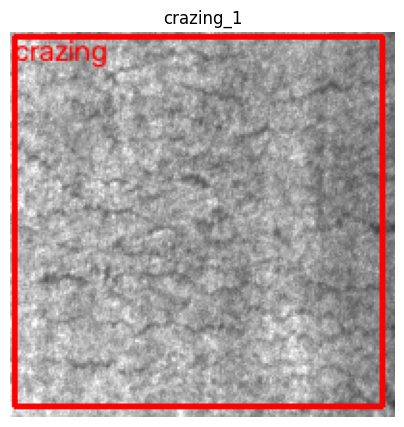

In [35]:
sample_image = next(TRAIN_IMAGES_DIR.glob("*.jpg"))
sample_label = TRAIN_LABELS_DIR / f"{sample_image.stem}.txt"

show_yolo_annotation(sample_image, sample_label)

In [36]:
multi_object_xml = next(
    xml_path
    for xml_path in annotations
    if len(read_annotation(xml_path)) >= 3
)

print("XML sélectionné :", multi_object_xml.name)
print("Nombre de défauts :", len(read_annotation(multi_object_xml)))

XML sélectionné : crazing_100.xml
Nombre de défauts : 4


In [37]:
multi_object_image = TRAIN_IMAGES_DIR / f"{multi_object_xml.stem}.jpg"
multi_object_label = TRAIN_LABELS_DIR / f"{multi_object_xml.stem}.txt"

print("Image :", multi_object_image.name)
print("Label :", multi_object_label.name)

print("\nContenu du fichier YOLO :")
print(multi_object_label.read_text())

Image : crazing_100.jpg
Label : crazing_100.txt

Contenu du fichier YOLO :
0 0.272500 0.327500 0.535000 0.555000
0 0.587500 0.210000 0.825000 0.410000
0 0.790000 0.767500 0.380000 0.445000
0 0.430000 0.755000 0.780000 0.390000


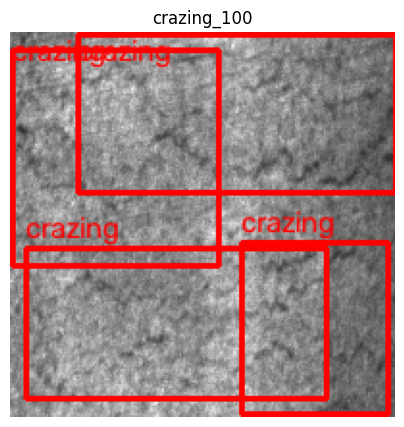

In [38]:
show_yolo_annotation(
    multi_object_image,
    multi_object_label
)

In [39]:
DATA_YAML = PROCESSED_DIR / "data.yaml"

yaml_content = f"""train: images/train
val: images/val
test: images/test

nc: {len(CLASS_NAMES)}

names:
"""

for class_name in CLASS_NAMES:
    yaml_content += f"  - {class_name}\n"

DATA_YAML.write_text(yaml_content, encoding="utf-8")

print(yaml_content)

train: images/train
val: images/val
test: images/test

nc: 6

names:
  - crazing
  - inclusion
  - patches
  - pitted_surface
  - rolled-in_scale
  - scratches



In [40]:
print("=== STRUCTURE DU DATASET YOLO ===\n")

print("Images :")
print("  Train      :", len(list(TRAIN_IMAGES_DIR.glob("*.jpg"))))
print("  Validation :", len(list(VAL_IMAGES_DIR.glob("*.jpg"))))
print("  Test       :", len(list(TEST_IMAGES_DIR.glob("*.jpg"))))

print("\nLabels :")
print("  Train      :", len(list(TRAIN_LABELS_DIR.glob("*.txt"))))
print("  Validation :", len(list(VAL_LABELS_DIR.glob("*.txt"))))
print("  Test       :", len(list(TEST_LABELS_DIR.glob("*.txt"))))

print("\nConfiguration :")
print("  Classes    :", len(CLASS_NAMES))
print("  data.yaml  :", DATA_YAML)

=== STRUCTURE DU DATASET YOLO ===

Images :
  Train      : 1260
  Validation : 270
  Test       : 270

Labels :
  Train      : 1260
  Validation : 270
  Test       : 270

Configuration :
  Classes    : 6
  data.yaml  : c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\data.yaml


In [41]:
def find_missing_labels(image_dir, label_dir):
    image_stems = {
        image.stem
        for image in image_dir.glob("*.jpg")
    }

    label_stems = {
        label.stem
        for label in label_dir.glob("*.txt")
    }

    return image_stems - label_stems


missing_train = find_missing_labels(
    TRAIN_IMAGES_DIR,
    TRAIN_LABELS_DIR
)

missing_val = find_missing_labels(
    VAL_IMAGES_DIR,
    VAL_LABELS_DIR
)

missing_test = find_missing_labels(
    TEST_IMAGES_DIR,
    TEST_LABELS_DIR
)

print("Images train sans label :", len(missing_train))
print("Images val sans label   :", len(missing_val))
print("Images test sans label  :", len(missing_test))

Images train sans label : 0
Images val sans label   : 0
Images test sans label  : 0


In [42]:
invalid_labels = []

for label_dir in [
    TRAIN_LABELS_DIR,
    VAL_LABELS_DIR,
    TEST_LABELS_DIR
]:
    for label_path in label_dir.glob("*.txt"):

        with open(label_path, "r", encoding="utf-8") as file:
            lines = file.readlines()

        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            if len(values) != 5:
                invalid_labels.append({
                    "file": label_path.name,
                    "line": line_number,
                    "reason": "Nombre de valeurs incorrect"
                })
                continue

            class_id, x, y, width, height = map(float, values)

            if not 0 <= class_id < len(CLASS_NAMES):
                invalid_labels.append({
                    "file": label_path.name,
                    "line": line_number,
                    "reason": "Class ID invalide"
                })

            if not (
                0 <= x <= 1
                and 0 <= y <= 1
                and 0 <= width <= 1
                and 0 <= height <= 1
            ):
                invalid_labels.append({
                    "file": label_path.name,
                    "line": line_number,
                    "reason": "Coordonnée hors [0,1]"
                })

print("Labels invalides :", len(invalid_labels))

Labels invalides : 0
